You call `.fit()`. A second later something is trained. **What happened in that second?**

Every other walkthrough in this series opens one specific algorithm. This one opens the
thing they all share: the idea of *learning from data*. It is the notebook to read first,
and the one to come back to, because every term used elsewhere &mdash; loss, gradient,
learning rate, bias, variance, overfitting, regularisation &mdash; is defined here with
numbers you can check on paper.

The claim being unpacked is this: **training is not magic and it is not search over
programs.** It is a loop of four steps repeated until the numbers stop improving.

> **guess &rarr; measure how wrong &rarr; work out which way is less wrong &rarr; move a little &rarr; repeat**

Everything below is that sentence, made arithmetic. The datasets are tiny on purpose:
small enough that every quantity is printed in full, so nothing has to be taken on faith.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


In [2]:
def draw_flow(steps, title="", loop_label="", ax=None, figsize=(13.5, 3.4),
              fontsize=9):
    """Draw a left-to-right flow of boxes with a feedback arrow underneath."""
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=figsize)
    n = len(steps)
    W, H, GAP = 2.5, 1.25, 0.95
    for i, (head, body, col) in enumerate(steps):
        x = i * (W + GAP)
        ax.add_patch(plt.Rectangle((x, -H/2), W, H, fc=col, ec="#334155",
                                   lw=1.8, zorder=3,
                                   joinstyle="round"))
        ax.text(x + W/2, H/2 - 0.28, head, ha="center", va="center",
                fontsize=fontsize + 1, fontweight="bold", zorder=4)
        ax.text(x + W/2, -0.12, body, ha="center", va="center",
                fontsize=fontsize - 1.2, zorder=4, family="monospace")
        if i < n - 1:
            ax.annotate("", xy=(x + W + GAP - 0.06, 0), xytext=(x + W + 0.06, 0),
                        arrowprops=dict(arrowstyle="-|>", lw=2.2, color="#334155"))
    # feedback path drawn explicitly (down, left, up) so it never crosses a box
    total = (n - 1) * (W + GAP) + W
    yb = -H/2 - 0.62
    x_from, x_to = total - W/2, W/2
    ax.plot([x_from, x_from], [-H/2, yb], color="#b91c1c", lw=2.0, zorder=2)
    ax.plot([x_from, x_to], [yb, yb], color="#b91c1c", lw=2.0, zorder=2)
    ax.annotate("", xy=(x_to, -H/2), xytext=(x_to, yb),
                arrowprops=dict(arrowstyle="-|>", lw=2.0, color="#b91c1c"))
    if loop_label:
        ax.text((x_from + x_to)/2, yb - 0.26, loop_label, ha="center", va="top",
                fontsize=fontsize, color="#b91c1c", fontweight="bold")
    ax.set_xlim(-0.6, total + 0.6)
    ax.set_ylim(yb - 0.95, H/2 + 0.5)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    if own:
        plt.tight_layout(); plt.show()
    return ax


print("Flow diagram helper ready: draw_flow(steps, title, loop_label).")

Flow diagram helper ready: draw_flow(steps, title, loop_label).


---
# 1. What a Model Actually Is

Before learning can be discussed, it is worth being precise about what is being learned.

A model is two things:

1. **A family of functions**, fixed in advance by you. `LinearRegression` says "my answer
   will have the form $w_0 + w_1x$". A decision tree says "my answer will be a series of
   threshold questions". Nothing outside the family can ever be produced, no matter how
   much data arrives.
2. **Parameters**, the dials that pick one member out of that family.

So "training" is not the model inventing anything. **The shape of the answer was chosen
by you when you picked the algorithm.** Training only turns the dials.

$$\underbrace{\hat{y} = w_0 + w_1 x}_{\text{the family: chosen by you}}
\qquad
\underbrace{w_0 = 1.4,\; w_1 = 0.8}_{\text{the parameters: found by training}}$$

This is why "which algorithm should I use?" matters so much: it is the question of which
shapes of answer are even reachable.

In [3]:
# a deliberately tiny dataset: 8 points, so nothing is hidden
x = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0])
y = np.array([2.1, 3.9, 6.2, 7.8, 10.1, 12.2, 13.8, 16.1])
n = len(x)
ids = [f"p{i}" for i in range(n)]

print("the data - 8 points, and that is the whole training set\n")
print(f"{'id':>4}  {'x':>6}  {'y':>7}")
print("-" * 22)
for i in range(n):
    print(f"{ids[i]:>4}  {x[i]:>6.1f}  {y[i]:>7.1f}")
print("-" * 22)

print("\nthree DIFFERENT families of function, each with its own parameters:\n")
print("   straight line   y = w0 + w1*x                    2 parameters")
print("   parabola        y = w0 + w1*x + w2*x^2           3 parameters")
print("   constant        y = w0                           1 parameter")

print("\nwhat each family can produce, using some arbitrary parameter values:\n")
print(f"{'x':>5}  {'line (1+2x)':>12}  {'parabola (1+2x-0.1x^2)':>24}  {'constant (9)':>13}")
print("-" * 60)
for xi in x[:4]:
    print(f"{xi:>5.1f}  {1+2*xi:>12.2f}  {1+2*xi-0.1*xi**2:>24.2f}  {9.0:>13.2f}")
print("-" * 60)
print("\nThe constant family can NEVER produce a sloped answer - not with any")
print("parameter value, not with any amount of data. That is a limit of the")
print("family, not of the training. Choosing the algorithm chooses the limits.")

the data - 8 points, and that is the whole training set

  id       x        y
----------------------
  p0     1.0      2.1
  p1     2.0      3.9
  p2     3.0      6.2
  p3     4.0      7.8
  p4     5.0     10.1
  p5     6.0     12.2
  p6     7.0     13.8
  p7     8.0     16.1
----------------------

three DIFFERENT families of function, each with its own parameters:

   straight line   y = w0 + w1*x                    2 parameters
   parabola        y = w0 + w1*x + w2*x^2           3 parameters
   constant        y = w0                           1 parameter

what each family can produce, using some arbitrary parameter values:

    x   line (1+2x)    parabola (1+2x-0.1x^2)   constant (9)
------------------------------------------------------------
  1.0          3.00                      2.90           9.00
  2.0          5.00                      4.60           9.00
  3.0          7.00                      6.10           9.00
  4.0          9.00                      7.40           9.0

---
# 2. The Loss &mdash; Turning "Wrong" Into a Number

Learning needs a target to improve. That means "how wrong is this model?" has to become a
single number, because you cannot minimise a feeling.

$$\text{loss} = \text{one number summarising all the errors}$$

Start with the per-point error, then decide how to combine them. The choice of *how* is
not cosmetic &mdash; it changes what the model ends up believing.

In [4]:
w0_try, w1_try = 0.5, 1.8          # some guess, not yet trained
pred = w0_try + w1_try * x
err = y - pred

print(f"a guess: w0 = {w0_try}, w1 = {w1_try}\n")
print(f"{'id':>4}  {'x':>5}  {'y':>7}  {'prediction':>18}  {'error':>9}  "
      f"{'|error|':>8}  {'error^2':>9}")
print("-" * 70)
for i in range(n):
    print(f"{ids[i]:>4}  {x[i]:>5.1f}  {y[i]:>7.1f}  "
          f"{w0_try} + {w1_try}*{x[i]:.0f} = {pred[i]:>6.2f}  {err[i]:>9.3f}  "
          f"{abs(err[i]):>8.3f}  {err[i]**2:>9.4f}")
print("-" * 70)
print(f"{'':>4}  {'':>5}  {'':>7}  {'SUM':>18}  {err.sum():>9.3f}  "
      f"{np.abs(err).sum():>8.3f}  {(err**2).sum():>9.4f}")

print(f"\nthree ways to make one number out of that column:\n")
print(f"   sum of errors        = {err.sum():+.4f}   <- USELESS: +3 and -3 cancel")
print(f"   mean absolute error  = {np.abs(err).sum():.4f} / {n} = {np.abs(err).mean():.4f}")
print(f"   mean squared error   = {(err**2).sum():.4f} / {n} = {(err**2).mean():.4f}")

print(f"\nThe first is discarded immediately: a model that is +10 on one point and")
print(f"-10 on another would score a perfect 0. Errors must be made positive")
print(f"first, either by |.| or by squaring.")

a guess: w0 = 0.5, w1 = 1.8

  id      x        y          prediction      error   |error|    error^2
----------------------------------------------------------------------
  p0    1.0      2.1  0.5 + 1.8*1 =   2.30     -0.200     0.200     0.0400
  p1    2.0      3.9  0.5 + 1.8*2 =   4.10     -0.200     0.200     0.0400
  p2    3.0      6.2  0.5 + 1.8*3 =   5.90      0.300     0.300     0.0900
  p3    4.0      7.8  0.5 + 1.8*4 =   7.70      0.100     0.100     0.0100
  p4    5.0     10.1  0.5 + 1.8*5 =   9.50      0.600     0.600     0.3600
  p5    6.0     12.2  0.5 + 1.8*6 =  11.30      0.900     0.900     0.8100
  p6    7.0     13.8  0.5 + 1.8*7 =  13.10      0.700     0.700     0.4900
  p7    8.0     16.1  0.5 + 1.8*8 =  14.90      1.200     1.200     1.4400
----------------------------------------------------------------------
                                     SUM      3.400     4.200     3.2800

three ways to make one number out of that column:

   sum of errors        = +3.40

### Squaring vs absolute value is a real decision

They are not two spellings of the same thing. Squaring makes a big error count
*disproportionately*: an error of 4 costs 16, while four errors of 1 cost 4 in total. So
squared loss will contort the model to avoid one large mistake.

The consequence is provable and worth knowing:

$$\text{minimising } \sum(y_i - c)^2 \;\Rightarrow\; c = \text{mean}(y)
\qquad\qquad
\text{minimising } \sum|y_i - c| \;\Rightarrow\; c = \text{median}(y)$$

**The loss you pick decides what "typical" means to your model.** That is why squared
loss is sensitive to outliers and absolute loss is not.

data plus one outlier: [2.1, 3.9, 6.2, 7.8, 10.1, 12.2, 13.8, 16.1, 60.0]

searching every constant c from 0 to 30 for the one that minimises each loss:

      c    mean squared    mean absolute
----------------------------------------
    8.0        320.0222           9.3556
   10.0        297.2667           9.1333
   12.0        282.5111           9.3333
   14.0        275.7556          10.0000
   16.0        277.0000          11.1111
   18.0        286.2444          12.6444
----------------------------------------

best c under squared loss  : 14.6900
mean of the data           : 14.6889   MATCH: True

best c under absolute loss : 10.1000
median of the data         : 10.1000   MATCH: True

The single outlier at 60 dragged the squared-loss answer to 14.69,
while the absolute-loss answer stayed at 10.10, near the bulk of
the data. Same data, same 'best' - two different definitions of best.


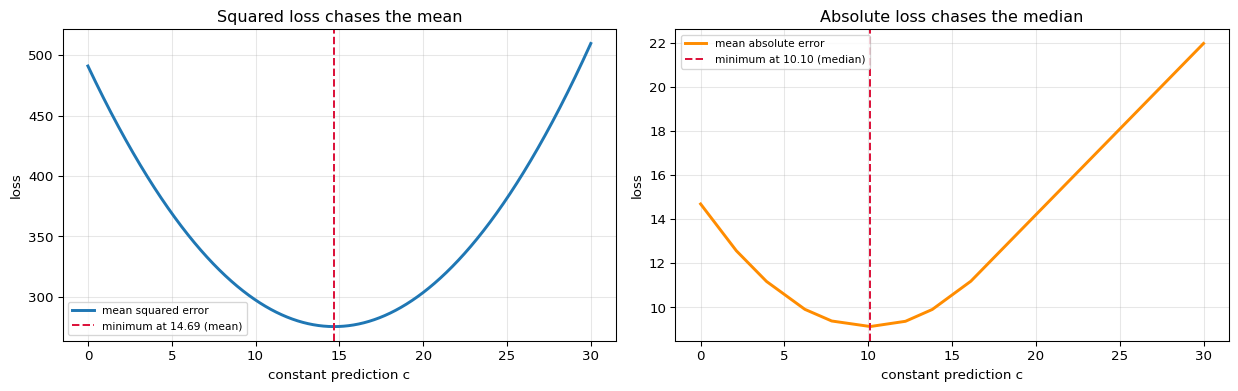

Note the shapes: squared loss is a smooth bowl (differentiable everywhere),
absolute loss has a kink at the minimum. That kink is exactly why squared
loss is the default - it is easier to optimise, as the next section shows.


In [5]:
y_out = np.append(y, 60.0)        # one wild outlier
print(f"data plus one outlier: {y_out.tolist()}\n")

grid_c = np.linspace(0, 30, 3001)
sq_loss = [((y_out - c)**2).mean() for c in grid_c]
ab_loss = [np.abs(y_out - c).mean() for c in grid_c]
best_sq = grid_c[int(np.argmin(sq_loss))]
best_ab = grid_c[int(np.argmin(ab_loss))]

print(f"searching every constant c from 0 to 30 for the one that minimises each loss:\n")
print(f"{'c':>7}  {'mean squared':>14}  {'mean absolute':>15}")
print("-" * 40)
for c in (8.0, 10.0, 12.0, 14.0, 16.0, 18.0):
    print(f"{c:>7.1f}  {((y_out-c)**2).mean():>14.4f}  {np.abs(y_out-c).mean():>15.4f}")
print("-" * 40)
print(f"\nbest c under squared loss  : {best_sq:.4f}")
print(f"mean of the data           : {y_out.mean():.4f}   MATCH: "
      f"{np.isclose(best_sq, y_out.mean(), atol=0.02)}")
print(f"\nbest c under absolute loss : {best_ab:.4f}")
print(f"median of the data         : {np.median(y_out):.4f}   MATCH: "
      f"{np.isclose(best_ab, np.median(y_out), atol=0.02)}")

print(f"\nThe single outlier at 60 dragged the squared-loss answer to "
      f"{best_sq:.2f},")
print(f"while the absolute-loss answer stayed at {best_ab:.2f}, near the bulk of")
print(f"the data. Same data, same 'best' - two different definitions of best.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(grid_c, sq_loss, lw=2.2, label="mean squared error")
ax[0].axvline(best_sq, color="crimson", ls="--", label=f"minimum at {best_sq:.2f} (mean)")
ax[0].set(xlabel="constant prediction c", ylabel="loss", title="Squared loss chases the mean")
ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].plot(grid_c, ab_loss, lw=2.2, color="darkorange", label="mean absolute error")
ax[1].axvline(best_ab, color="crimson", ls="--", label=f"minimum at {best_ab:.2f} (median)")
ax[1].set(xlabel="constant prediction c", ylabel="loss", title="Absolute loss chases the median")
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Note the shapes: squared loss is a smooth bowl (differentiable everywhere),")
print("absolute loss has a kink at the minimum. That kink is exactly why squared")
print("loss is the default - it is easier to optimise, as the next section shows.")

---
# 3. The Learning Loop

With a loss defined, learning becomes a concrete question: **which parameter values make
this number small?**

For a two-parameter model you could try every combination. For a neural network with a
million parameters you obviously cannot. So instead of searching, learning uses a local
rule: from wherever you are, work out which direction is downhill, and step that way.

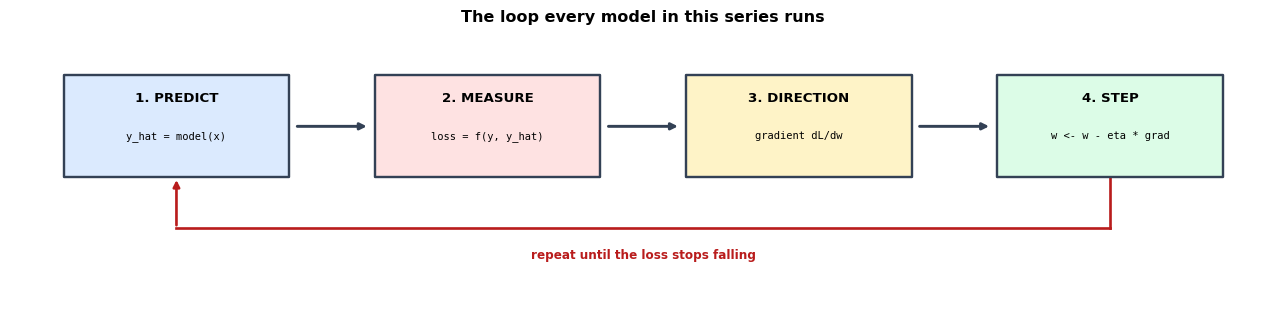

What changes between algorithms is only the CONTENTS of the boxes:

             algorithm              box 1: predict             box 2: loss
--------------------------------------------------------------------------
     Linear regression                   w0 + w1*x           squared error
   Logistic regression                sigmoid(w.x)                log-loss
        Neural network        layers + activations          log-loss / MSE
                   SVM               sign(w.x + b)         hinge + ||w||^2
               XGBoost                sum of trees        any, via g and h
--------------------------------------------------------------------------

The loop itself never changes. Decision trees and k-means are the
exceptions in this series - they minimise their objective by a different
device (greedy splitting, alternating assignment) - but even there the
skeleton is the same: measure, improve, repeat.


In [6]:
draw_flow(
    [("1. PREDICT",  "y_hat = model(x)",       "#dbeafe"),
     ("2. MEASURE",  "loss = f(y, y_hat)",     "#fee2e2"),
     ("3. DIRECTION","gradient dL/dw",         "#fef3c7"),
     ("4. STEP",     "w <- w - eta * grad",    "#dcfce7")],
    title="The loop every model in this series runs",
    loop_label="repeat until the loss stops falling")

print("What changes between algorithms is only the CONTENTS of the boxes:\n")
print(f"{'algorithm':>22}  {'box 1: predict':>26}  {'box 2: loss':>22}")
print("-" * 74)
rows = [("Linear regression", "w0 + w1*x", "squared error"),
        ("Logistic regression", "sigmoid(w.x)", "log-loss"),
        ("Neural network", "layers + activations", "log-loss / MSE"),
        ("SVM", "sign(w.x + b)", "hinge + ||w||^2"),
        ("XGBoost", "sum of trees", "any, via g and h")]
for a, b, c in rows:
    print(f"{a:>22}  {b:>26}  {c:>22}")
print("-" * 74)
print("\nThe loop itself never changes. Decision trees and k-means are the")
print("exceptions in this series - they minimise their objective by a different")
print("device (greedy splitting, alternating assignment) - but even there the")
print("skeleton is the same: measure, improve, repeat.")

---
# 4. The Gradient &mdash; Which Way Is Downhill

Box 3 is where the actual mathematics lives, and it is one idea: **the derivative tells
you how the loss responds to a nudge.**

$$\frac{\partial \mathcal{L}}{\partial w} \;\approx\; \frac{\mathcal{L}(w + \epsilon) - \mathcal{L}(w - \epsilon)}{2\epsilon}$$

Read it as a rate of exchange: *if I increase $w$ by one unit, the loss changes by this
much.* Three cases, and the rule follows from them:

| Derivative | Meaning | What to do |
|---|---|---|
| positive | increasing $w$ makes things **worse** | **decrease** $w$ |
| negative | increasing $w$ makes things **better** | **increase** $w$ |
| zero | flat &mdash; a nudge either way changes nothing | **stop** |

All three cases are "move opposite the derivative", which is why the update is
$w \leftarrow w - \eta\,\partial\mathcal{L}/\partial w$ &mdash; **the minus sign is the whole
algorithm.**

In [7]:
def loss_w1(w1_, w0_=0.0):
    return float(np.mean((y - (w0_ + w1_*x))**2))

print("hold w0 = 0 and vary only the slope w1, so the loss is a curve we can walk\n")
print(f"{'w1':>7}  {'loss':>11}  {'numerical derivative':>22}  {'reading':>28}")
print("-" * 74)
EPS = 1e-5
for w1_ in (0.0, 0.5, 1.0, 1.5, 1.9, 2.0, 2.5, 3.0):
    L = loss_w1(w1_)
    d = (loss_w1(w1_+EPS) - loss_w1(w1_-EPS)) / (2*EPS)
    if d < -1e-6:
        r = "downhill to the RIGHT"
    elif d > 1e-6:
        r = "downhill to the LEFT"
    else:
        r = "FLAT - this is the bottom"
    print(f"{w1_:>7.2f}  {L:>11.5f}  {d:>22.6f}  {r:>28}")
print("-" * 74)

print(f"\none derivative worked out fully, at w1 = 1.0:\n")
w1_ = 1.0
Lp, Lm = loss_w1(w1_+EPS), loss_w1(w1_-EPS)
print(f"   loss at w1 = {w1_+EPS:.5f}  ->  {Lp:.10f}")
print(f"   loss at w1 = {w1_-EPS:.5f}  ->  {Lm:.10f}")
print(f"   change in loss          = {Lp-Lm:+.10f}")
print(f"   change in w1            = {2*EPS:.10f}")
print(f"   ratio (the derivative)  = {(Lp-Lm)/(2*EPS):+.6f}")

analytic = float(np.mean(2*((w1_*x) - y)*x))
print(f"\n   the same thing from calculus, dL/dw1 = (2/n) * sum((w1*x - y)*x):")
terms = (w1_*x - y)*x
print(f"      = (2/{n}) * ({' + '.join(f'{v:+.2f}' for v in terms[:5])} + ...)")
print(f"      = (2/{n}) * {terms.sum():+.6f} = {analytic:+.6f}")
print(f"   numerical: {(Lp-Lm)/(2*EPS):+.6f}   MATCH: "
      f"{np.isclose(analytic, (Lp-Lm)/(2*EPS), atol=1e-4)}")
print(f"\n   Negative, so the loss falls if w1 increases - and indeed the bottom")
print(f"   of the curve is further right, near w1 = 2.")

hold w0 = 0 and vary only the slope w1, so the loss is a curve we can walk

     w1         loss    numerical derivative                       reading
--------------------------------------------------------------------------
   0.00    102.42500             -102.200000         downhill to the RIGHT
   0.50     57.70000              -76.700000         downhill to the RIGHT
   1.00     25.72500              -51.200000         downhill to the RIGHT
   1.50      6.50000              -25.700000         downhill to the RIGHT
   1.90      0.30000               -5.300000         downhill to the RIGHT
   2.00      0.02500               -0.200000         downhill to the RIGHT
   2.50      6.30000               25.300000          downhill to the LEFT
   3.00     25.32500               50.800000          downhill to the LEFT
--------------------------------------------------------------------------

one derivative worked out fully, at w1 = 1.0:

   loss at w1 = 1.00001  ->  25.7244880025
   loss 

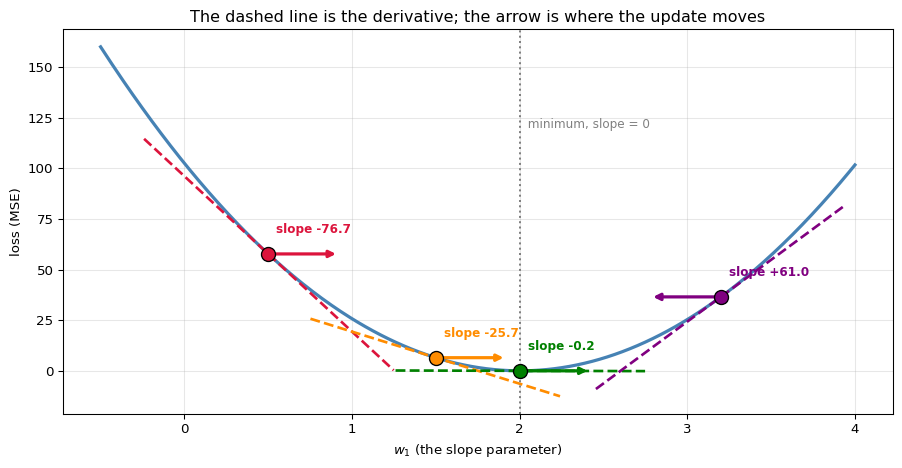

Every arrow points toward the bottom, and every arrow points OPPOSITE its
dashed tangent line. That is the minus sign doing its job.

At the minimum (w1 = 2.004) the tangent is horizontal - the
derivative is zero, no direction improves anything, and learning stops.
'Converged' means exactly this and nothing more.


In [8]:
w1_grid = np.linspace(-0.5, 4.0, 400)
L_grid = [loss_w1(v) for v in w1_grid]
w1_best = w1_grid[int(np.argmin(L_grid))]

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(w1_grid, L_grid, lw=2.4, color="steelblue")
for w1_, col in [(0.5, "crimson"), (1.5, "darkorange"), (2.0, "green"), (3.2, "purple")]:
    L = loss_w1(w1_)
    d = (loss_w1(w1_+EPS) - loss_w1(w1_-EPS)) / (2*EPS)
    tang = L + d*(w1_grid - w1_)
    m = np.abs(w1_grid - w1_) < 0.75
    ax.plot(w1_grid[m], tang[m], lw=2, color=col, ls="--")
    ax.scatter([w1_], [L], s=110, color=col, zorder=5, edgecolor="k")
    ax.annotate(f"slope {d:+.1f}", (w1_, L), textcoords="offset points",
                xytext=(6, 16), fontsize=9, color=col, fontweight="bold")
    if abs(d) > 1e-6:
        ax.annotate("", xy=(w1_ - 0.42*np.sign(d), L), xytext=(w1_, L),
                    arrowprops=dict(arrowstyle="-|>", lw=2.4, color=col))
ax.axvline(w1_best, color="grey", ls=":", lw=1.5)
ax.text(w1_best, max(L_grid)*.75, f"  minimum, slope = 0", fontsize=9, color="grey")
ax.set(xlabel="$w_1$ (the slope parameter)", ylabel="loss (MSE)",
       title="The dashed line is the derivative; the arrow is where the update moves")
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Every arrow points toward the bottom, and every arrow points OPPOSITE its")
print("dashed tangent line. That is the minus sign doing its job.")
print(f"\nAt the minimum (w1 = {w1_best:.3f}) the tangent is horizontal - the")
print("derivative is zero, no direction improves anything, and learning stops.")
print("'Converged' means exactly this and nothing more.")

---
# 5. The Learning Rate &mdash; How Big a Step

The gradient gives a *direction* but not a *distance*. The learning rate $\eta$ supplies
the distance, and it is the single most consequential number you set by hand.

$$w \leftarrow w - \eta\,\frac{\partial\mathcal{L}}{\partial w}$$

Three regimes, all visible below:

* **$\eta$ too small** &mdash; correct every step, but arrives too slowly to be useful
* **$\eta$ about right** &mdash; steady approach, steps shortening naturally as the gradient shrinks
* **$\eta$ too large** &mdash; each step jumps *past* the minimum onto the opposite wall, where the gradient is larger still, so the next jump is worse. The loss **increases** and the model diverges.

Note the third case carefully: nothing is wrong with the direction. It is right every
single time. Only the step length is wrong.

In [9]:
def descend(eta, steps=40, w_start=0.0):
    w_, hist = w_start, [w_start]
    for _ in range(steps):
        d = (loss_w1(w_+EPS) - loss_w1(w_-EPS)) / (2*EPS)
        w_ = w_ - eta*d
        if not np.isfinite(w_) or abs(w_) > 1e6:
            hist.append(np.nan); break
        hist.append(w_)
    return np.array(hist)

print("the first six steps at three learning rates, starting from w1 = 0\n")
for eta in (0.002, 0.02, 0.07):
    h = descend(eta, steps=6)
    print(f"eta = {eta}")
    for k in range(len(h)-1):
        if not np.isfinite(h[k]):
            print(f"   step {k}: diverged"); break
        d = (loss_w1(h[k]+EPS) - loss_w1(h[k]-EPS)) / (2*EPS)
        print(f"   step {k}: w1 = {h[k]:>9.4f}   loss = {loss_w1(h[k]):>10.4f}   "
              f"grad = {d:>10.4f}   ->  w1 = {h[k]:.4f} - {eta}*({d:.4f}) = "
              f"{h[k+1]:>9.4f}")
    print()

H = float(np.mean(2*x*x))          # second derivative of the loss w.r.t. w1
print(f"the stability limit, from the curvature of the loss:")
print(f"   d2L/dw1^2 = (2/n) * sum(x^2) = {H:.6f}")
print(f"   gradient descent is stable while eta < 2 / {H:.6f} = {2/H:.6f}")
print(f"\n   eta = 0.002  ->  {0.002/(2/H):.2f}x the limit  : converges, slowly")
print(f"   eta = 0.020  ->  {0.020/(2/H):.2f}x the limit  : converges well")
print(f"   eta = 0.070  ->  {0.070/(2/H):.2f}x the limit  : DIVERGES")

the first six steps at three learning rates, starting from w1 = 0

eta = 0.002
   step 0: w1 =    0.0000   loss =   102.4250   grad =  -102.2000   ->  w1 = 0.0000 - 0.002*(-102.2000) =    0.2044
   step 1: w1 =    0.2044   loss =    82.6007   grad =   -91.7756   ->  w1 = 0.2044 - 0.002*(-91.7756) =    0.3880
   step 2: w1 =    0.3880   loss =    66.6143   grad =   -82.4145   ->  w1 = 0.3880 - 0.002*(-82.4145) =    0.5528
   step 3: w1 =    0.5528   loss =    53.7228   grad =   -74.0082   ->  w1 = 0.5528 - 0.002*(-74.0082) =    0.7008
   step 4: w1 =    0.7008   loss =    43.3270   grad =   -66.4594   ->  w1 = 0.7008 - 0.002*(-66.4594) =    0.8337
   step 5: w1 =    0.8337   loss =    34.9439   grad =   -59.6805   ->  w1 = 0.8337 - 0.002*(-59.6805) =    0.9531

eta = 0.02
   step 0: w1 =    0.0000   loss =   102.4250   grad =  -102.2000   ->  w1 = 0.0000 - 0.02*(-102.2000) =    2.0440
   step 1: w1 =    2.0440   loss =     0.0656   grad =     2.0440   ->  w1 = 2.0440 - 0.02*(2.0440) =  

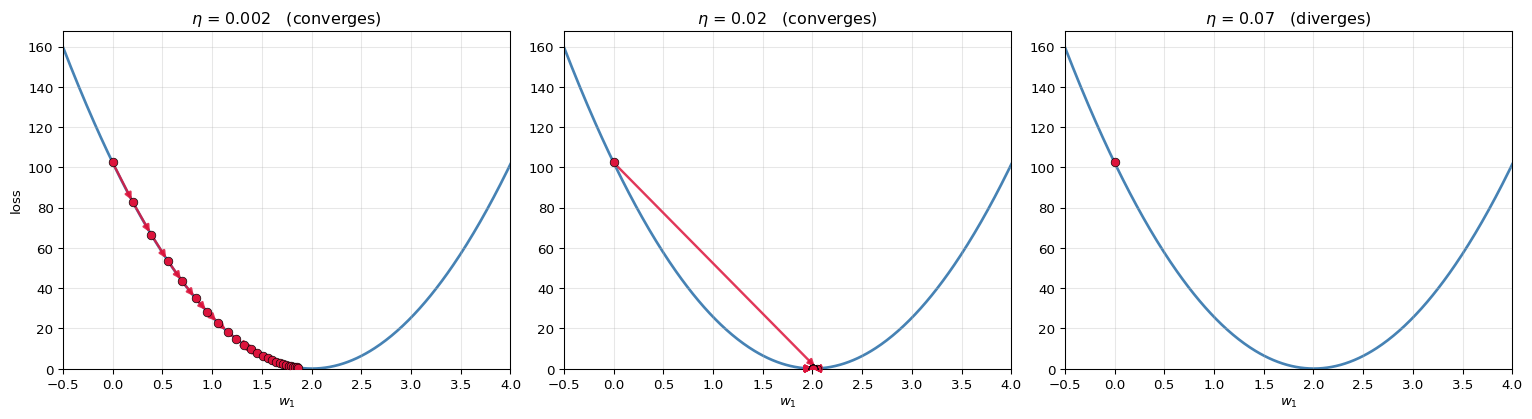

Left  : tiny steps, still far from the bottom after 25 of them.
Middle: steps shorten by themselves as the slope flattens - no tuning needed.
Right : each step overshoots to a HIGHER point on the far wall, so the
        next gradient is larger and the next jump bigger still.


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, eta in zip(axes, (0.002, 0.02, 0.07)):
    ax.plot(w1_grid, L_grid, lw=2, color="steelblue", zorder=1)
    h = descend(eta, steps=25)
    h = h[np.isfinite(h)]
    for k in range(len(h)-1):
        ax.annotate("", xy=(h[k+1], loss_w1(h[k+1]) if abs(h[k+1]) < 5 else max(L_grid)),
                    xytext=(h[k], loss_w1(h[k]) if abs(h[k]) < 5 else max(L_grid)),
                    arrowprops=dict(arrowstyle="-|>", lw=1.8, color="crimson", alpha=.85))
    inside = h[np.abs(h) < 4.5]
    ax.scatter(inside, [loss_w1(v) for v in inside], s=42, color="crimson",
               zorder=5, edgecolor="k", linewidths=.5)
    verdict = "diverges" if (not np.isfinite(descend(eta, 40)[-1])
                             or abs(descend(eta, 40)[-1]) > 10) else "converges"
    ax.set(xlim=(-0.5, 4.0), ylim=(0, max(L_grid)*1.05),
           xlabel="$w_1$", title=f"$\\eta$ = {eta}   ({verdict})")
    if eta == 0.002:
        ax.set_ylabel("loss")
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Left  : tiny steps, still far from the bottom after 25 of them.")
print("Middle: steps shorten by themselves as the slope flattens - no tuning needed.")
print("Right : each step overshoots to a HIGHER point on the far wall, so the")
print("        next gradient is larger and the next jump bigger still.")

---
# 6. Where Error Comes From: Bias, Variance, Noise

Now the concepts that decide whether a trained model is any good.

Suppose there is a true relationship $f(x)$, and what we observe is that plus
unpredictable noise:

$$y = f(x) + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma^2)$$

Train on one dataset and you get one model. Train on a *different* sample from the same
source and you get a slightly different model. Repeating that, the expected squared error
at a point splits into exactly three parts:

$$\underbrace{\mathbb{E}\big[(y - \hat{f}(x))^2\big]}_{\text{total error}}
=
\underbrace{\big(\mathbb{E}[\hat{f}(x)] - f(x)\big)^2}_{\textbf{bias}^2}
+
\underbrace{\mathbb{E}\big[(\hat{f}(x) - \mathbb{E}[\hat{f}(x)])^2\big]}_{\textbf{variance}}
+
\underbrace{\sigma^2}_{\textbf{noise}}$$

In words, and this is the part worth memorising:

* **Bias** &mdash; how far the *average* model is from the truth. High bias = the family is too
  simple to represent $f$. It is wrong **consistently**.
* **Variance** &mdash; how much the model *changes* when the training data changes. High
  variance = it is chasing the particular noise in this sample. It is wrong
  **inconsistently**.
* **Noise** &mdash; the part nobody can ever predict. An error floor, not a fault of the model.

Below, all three are computed numerically from a known truth &mdash; and their sum is checked
against the measured total error.

In [11]:
rng = np.random.default_rng(0)

def f_true(t):
    return np.sin(1.3*t) * 3.0 + 0.6*t          # the truth, known only to us

SIGMA   = 1.0          # the noise level, also known to us
N_BV    = 40           # sample size for the bias/variance experiment
N_SMALL = 14           # a deliberately small set, used from section 7 on
N_SETS  = 400
# evaluate slightly inside the data range: a polynomial fitted on [0,6] is
# wildly unstable right at the edges, which would swamp the effect being shown
x_dom = np.linspace(0.3, 5.7, 200)

def sample_dataset(m=None):
    m = m or N_BV
    xs = rng.uniform(0, 6, m)
    return xs, f_true(xs) + rng.normal(0, SIGMA, m)

def fit_poly(xs, ys, deg):
    return np.polyfit(xs, ys, deg)

print(f"the experiment: draw {N_SETS} independent training sets of {N_BV} points")
print(f"from the SAME truth, fit a model to each, and see how the predictions")
print(f"scatter around the true function.\n")
print(f"   true f(x)   = 3*sin(1.3x) + 0.6x       (known to us, not to the model)")
print(f"   noise sigma = {SIGMA}  ->  irreducible error sigma^2 = {SIGMA**2}")

degrees = [0, 1, 2, 3, 5, 9]
results = {}
for deg in degrees:
    preds = np.zeros((N_SETS, len(x_dom)))
    for k in range(N_SETS):
        xs, ys = sample_dataset()
        preds[k] = np.polyval(fit_poly(xs, ys, deg), x_dom)
    mean_pred = preds.mean(axis=0)
    bias2 = float(np.mean((mean_pred - f_true(x_dom))**2))
    var = float(np.mean(preds.var(axis=0)))
    results[deg] = dict(preds=preds, mean=mean_pred, bias2=bias2, var=var)

print(f"\n{'degree':>7}  {'bias^2':>11}  {'variance':>11}  {'noise':>9}  "
      f"{'sum = expected err':>19}  {'character':>22}")
print("-" * 90)
for deg in degrees:
    r = results[deg]
    tot = r['bias2'] + r['var'] + SIGMA**2
    ch = ("far too simple" if deg <= 1 else "still too simple" if deg == 2 else
          "closer" if deg == 3 else "about right" if deg == 5 else
          "too flexible")
    print(f"{deg:>7}  {r['bias2']:>11.4f}  {r['var']:>11.4f}  {SIGMA**2:>9.4f}  "
          f"{tot:>19.4f}  {ch:>22}")
print("-" * 90)
print("\nRead the two middle columns as a see-saw: as the model gets more flexible,")
best_bv = min(degrees, key=lambda d: results[d]['bias2'] + results[d]['var'])
print(f"bias falls and variance rises. Degree {best_bv} is where their SUM is smallest -")
print("and that sum, not either column alone, is what we actually care about.")

the experiment: draw 400 independent training sets of 40 points
from the SAME truth, fit a model to each, and see how the predictions
scatter around the true function.

   true f(x)   = 3*sin(1.3x) + 0.6x       (known to us, not to the model)
   noise sigma = 1.0  ->  irreducible error sigma^2 = 1.0

 degree       bias^2     variance      noise   sum = expected err               character
------------------------------------------------------------------------------------------
      0       3.6794       0.1466     1.0000               4.8261          far too simple
      1       3.8182       0.2495     1.0000               5.0676          far too simple
      2       1.8991       0.2777     1.0000               3.1769        still too simple
      3       0.4881       0.2008     1.0000               1.6889                  closer
      5       0.0084       0.1722     1.0000               1.1806             about right
      9       0.0010       0.4860     1.0000               1.4869  

### Verifying the decomposition

The formula claims $\text{bias}^2 + \text{variance} + \sigma^2$ equals the expected
squared error on fresh data. That is a testable claim, not a definition &mdash; so it is
tested: measure the actual error on newly generated test points and compare.

In [12]:
print(f"measuring the true expected error directly, on fresh noisy test data\n")
print(f"{'degree':>7}  {'measured error':>15}  {'bias^2 + var + noise':>21}  "
      f"{'difference':>12}  {'match':>7}")
print("-" * 70)
for deg in degrees:
    r = results[deg]
    errs = []
    for k in range(N_SETS):
        y_test = f_true(x_dom) + rng.normal(0, SIGMA, len(x_dom))
        errs.append(np.mean((y_test - r['preds'][k])**2))
    measured = float(np.mean(errs))
    predicted = r['bias2'] + r['var'] + SIGMA**2
    ok = abs(measured - predicted) < 0.06 * max(predicted, 1)
    print(f"{deg:>7}  {measured:>15.4f}  {predicted:>21.4f}  "
          f"{measured-predicted:>+12.4f}  {str(ok):>7}")
print("-" * 70)
print("\nThe three parts add up to the error we actually observe. The")
print("decomposition is not a metaphor - it is an identity, and these are the")
print("numbers that confirm it.")

print(f"\n\nwhat the individual fits look like at one x, say x = 3.0:\n")
xi = int(np.argmin(np.abs(x_dom - 3.0)))
print(f"   true value f(3.0) = {f_true(x_dom[xi]):.4f}\n")
print(f"{'degree':>7}  {'mean prediction':>16}  {'bias':>9}  {'spread (sd)':>12}  "
      f"{'5 individual fits':>34}")
print("-" * 86)
for deg in degrees:
    r = results[deg]
    vals = r['preds'][:5, xi]
    print(f"{deg:>7}  {r['mean'][xi]:>16.4f}  {r['mean'][xi]-f_true(x_dom[xi]):>+9.4f}  "
          f"{r['preds'][:, xi].std():>12.4f}  "
          f"{'  '.join(f'{v:+6.2f}' for v in vals):>34}")
print("-" * 86)
print("\nDegree 0: every fit lands near the same wrong place - consistent, biased.")
print("Degree 12: the fits are scattered wildly - each one chased its own noise.")

measuring the true expected error directly, on fresh noisy test data

 degree   measured error   bias^2 + var + noise    difference    match
----------------------------------------------------------------------
      0           4.8120                 4.8261       -0.0140     True
      1           5.0422                 5.0676       -0.0254     True
      2           3.1854                 3.1769       +0.0086     True
      3           1.6852                 1.6889       -0.0037     True
      5           1.1836                 1.1806       +0.0030     True
      9           1.4861                 1.4869       -0.0008     True
----------------------------------------------------------------------

The three parts add up to the error we actually observe. The
decomposition is not a metaphor - it is an identity, and these are the
numbers that confirm it.


what the individual fits look like at one x, say x = 3.0:

   true value f(3.0) = -0.2327

 degree   mean prediction       bias   s

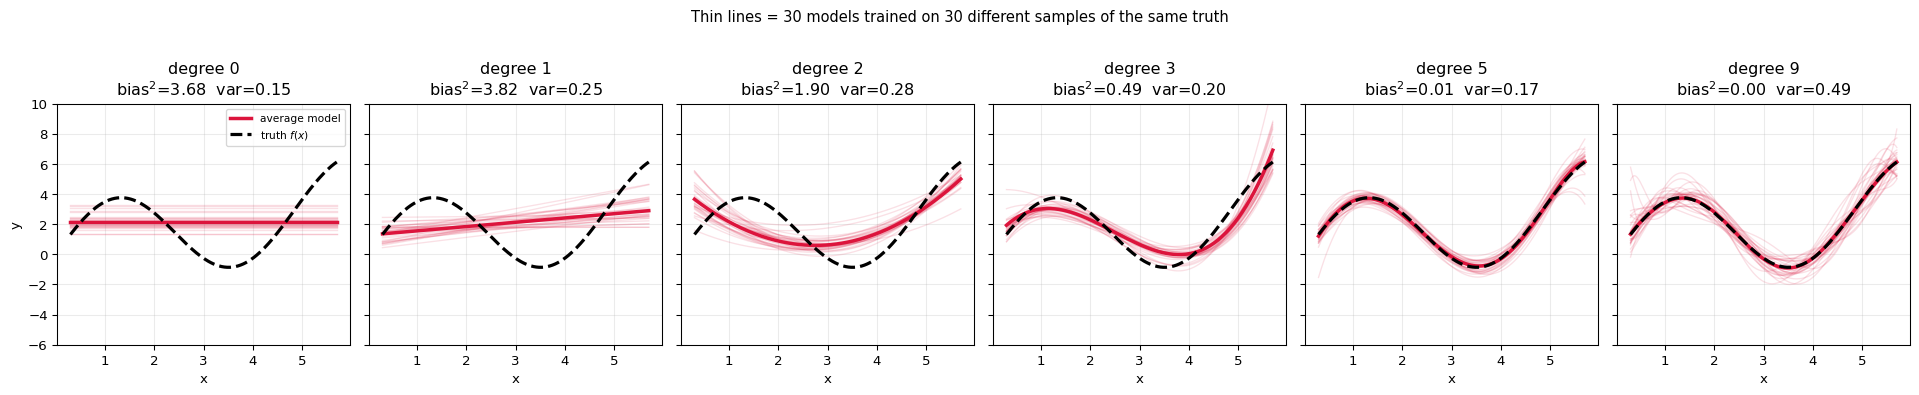

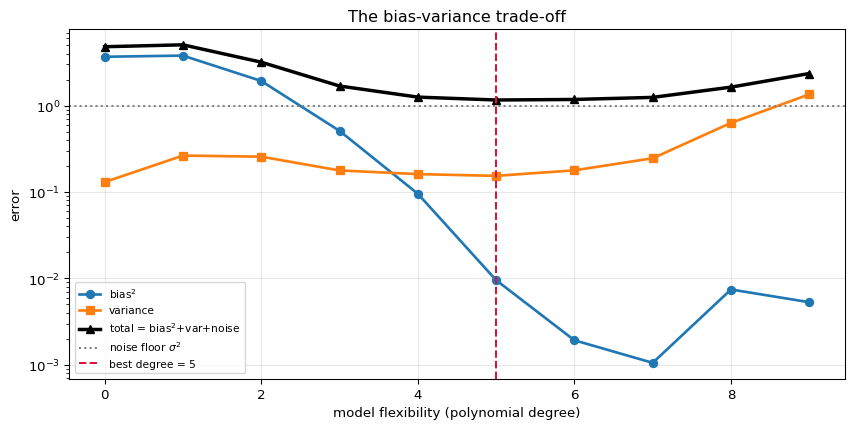

 degree      bias^2    variance       total
------------------------------------------
      0      3.6836      0.1304      4.8141
      1      3.8009      0.2643      5.0652
      2      1.9329      0.2569      3.1898
      3      0.5113      0.1779      1.6892
      4      0.0956      0.1612      1.2568
      5      0.0095      0.1540      1.1636  <== best
      6      0.0019      0.1784      1.1803
      7      0.0011      0.2461      1.2472
      8      0.0074      0.6319      1.6394
      9      0.0053      1.3524      2.3577
------------------------------------------

The total can never go below the noise floor of 1.00. Chasing
error below that is chasing randomness, and it is exactly what
overfitting is.


In [13]:
fig, axes = plt.subplots(1, len(degrees), figsize=(3.35*len(degrees), 4.0), sharey=True)
for ax, deg in zip(axes, degrees):
    r = results[deg]
    for k in range(30):
        ax.plot(x_dom, r['preds'][k], color="crimson", alpha=.13, lw=1)
    ax.plot(x_dom, r['mean'], color="crimson", lw=2.6, label="average model")
    ax.plot(x_dom, f_true(x_dom), color="k", lw=2.4, ls="--", label="truth $f(x)$")
    ax.set(ylim=(-6, 10), xlabel="x",
           title=f"degree {deg}\nbias$^2$={r['bias2']:.2f}  var={r['var']:.2f}")
    if deg == degrees[0]:
        ax.set_ylabel("y"); ax.legend(fontsize=8)
    ax.grid(alpha=.25)
plt.suptitle("Thin lines = 30 models trained on 30 different samples of the same truth",
             y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.6))
deg_fine = list(range(0, 10))
b2, vr = [], []
for deg in deg_fine:
    preds = np.zeros((150, len(x_dom)))
    for k in range(150):
        xs, ys = sample_dataset()
        preds[k] = np.polyval(fit_poly(xs, ys, deg), x_dom)
    b2.append(float(np.mean((preds.mean(axis=0) - f_true(x_dom))**2)))
    vr.append(float(np.mean(preds.var(axis=0))))
b2, vr = np.array(b2), np.array(vr)
tot = b2 + vr + SIGMA**2
ax.plot(deg_fine, b2, "o-", lw=2, label="bias$^2$")
ax.plot(deg_fine, vr, "s-", lw=2, label="variance")
ax.plot(deg_fine, tot, "^-", lw=2.6, color="k", label="total = bias$^2$+var+noise")
ax.axhline(SIGMA**2, ls=":", color="grey", label="noise floor $\\sigma^2$")
ax.axvline(deg_fine[int(np.argmin(tot))], ls="--", color="crimson",
           label=f"best degree = {deg_fine[int(np.argmin(tot))]}")
ax.set(xlabel="model flexibility (polynomial degree)", ylabel="error",
       yscale="log", title="The bias-variance trade-off")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"{'degree':>7}  {'bias^2':>10}  {'variance':>10}  {'total':>10}")
print("-" * 42)
for d_, a_, b_, t_ in zip(deg_fine, b2, vr, tot):
    mark = "  <== best" if d_ == deg_fine[int(np.argmin(tot))] else ""
    print(f"{d_:>7}  {a_:>10.4f}  {b_:>10.4f}  {t_:>10.4f}{mark}")
print("-" * 42)
print(f"\nThe total can never go below the noise floor of {SIGMA**2:.2f}. Chasing")
print(f"error below that is chasing randomness, and it is exactly what")
print(f"overfitting is.")

---
# 7. Underfitting and Overfitting

Those two failure modes have names, and now they have precise meanings:

| | Bias | Variance | Train error | Test error |
|---|---|---|---|---|
| **Underfitting** | high | low | **high** | high |
| Good fit | low | low | low | low |
| **Overfitting** | low | high | **very low** | **high** |

The diagnostic is the *gap*:

* Train error high **and** test error high &rarr; **underfitting**. The model is too simple;
  more data will not help.
* Train error near zero **but** test error high &rarr; **overfitting**. The model memorised
  the sample, including its noise.

This is why **training error is not a measure of quality.** A model can drive it to zero
by memorising, which is the opposite of learning.

In [14]:
xs_fix, ys_fix = sample_dataset(N_SMALL)   # ONE small training set, held fixed
# test points drawn from INSIDE the training range. A degree-13 polynomial
# fitted on 14 points diverges violently just outside the data, and that
# extrapolation artefact would dominate every number below.
x_te = rng.uniform(0.6, 5.4, 400)
y_te = f_true(x_te) + rng.normal(0, SIGMA, 400)

print(f"one training set of {N_SMALL} points, one test set of {len(x_te)} points")
print()
print(f"{'degree':>7}  {'params':>7}  {'train MSE':>11}  {'test MSE':>10}  "
      f"{'gap':>9}  {'diagnosis':>14}")
print("-" * 68)
tr_c, te_c, deg_list = [], [], list(range(0, 14))
for deg in deg_list:
    c = fit_poly(xs_fix, ys_fix, deg)
    tr = float(np.mean((ys_fix - np.polyval(c, xs_fix))**2))
    te = float(np.mean((y_te - np.polyval(c, x_te))**2))
    tr_c.append(tr); te_c.append(te)
    if tr > 2.5 and te > 2.5:
        diag = "UNDERFIT"
    elif te > 3*max(tr, 1e-9) and te > 2.0:
        diag = "OVERFIT"
    else:
        diag = "good"
    print(f"{deg:>7}  {deg+1:>7}  {tr:>11.4f}  {te:>10.4f}  {te-tr:>+9.4f}  "
          f"{diag:>14}")
print("-" * 68)
best_deg = deg_list[int(np.argmin(te_c))]
print(f"\nlowest TEST error at degree {best_deg}")
print(f"lowest TRAIN error at degree {deg_list[int(np.argmin(tr_c))]}  "
      f"<- train error just keeps falling, and says nothing useful")
print()
print(f"training points: {N_SMALL}.  At degree {N_SMALL-1} the polynomial has as many")
print(f"free parameters as there are points, so it can pass EXACTLY through every")
print(f"one of them - train error zero, and a useless model.")

one training set of 14 points, one test set of 400 points

 degree   params    train MSE    test MSE        gap       diagnosis
--------------------------------------------------------------------
      0        1       1.8507      4.2610    +2.4103            good
      1        2       1.7182      4.6218    +2.9036            good
      2        3       1.7180      4.5971    +2.8791            good
      3        4       0.3324      1.3147    +0.9822            good
      4        5       0.3227      1.2020    +0.8793            good
      5        6       0.3225      1.1708    +0.8483            good
      6        7       0.3221      1.1441    +0.8220            good
      7        8       0.3033      2.0471    +1.7438         OVERFIT
      8        9       0.2973      9.2424    +8.9450         OVERFIT
      9       10       0.2144     42.5831   +42.3687         OVERFIT
     10       11       0.1999     47.6812   +47.4814         OVERFIT
     11       12       0.1230   1652.4057  +

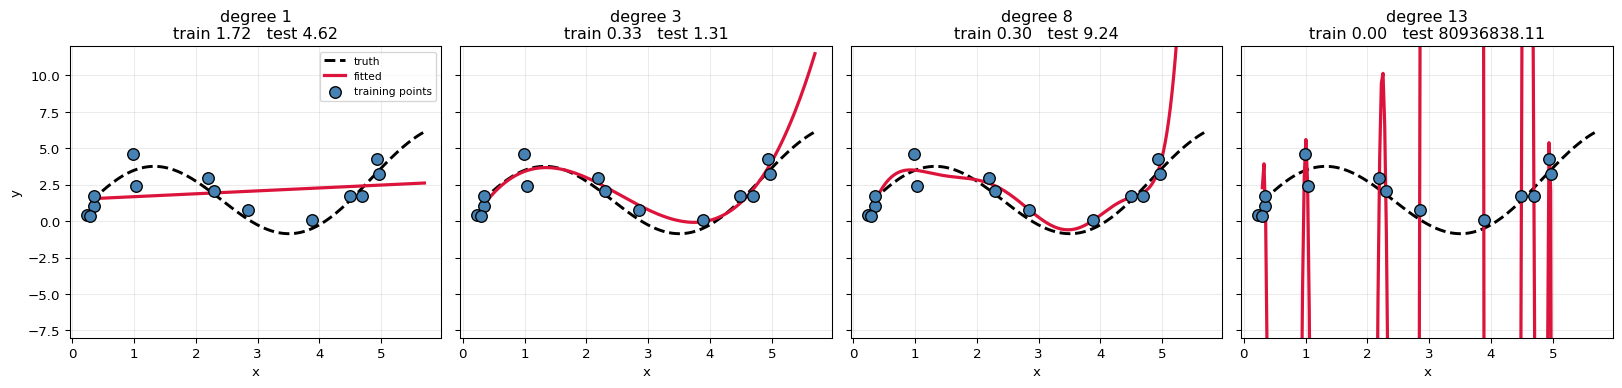

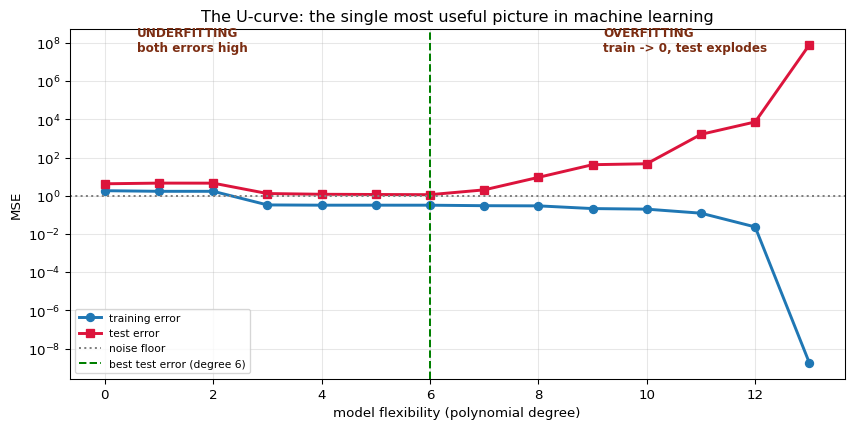

Degree 13 passes through every training point perfectly and is wrong
everywhere between them. It has learned the SAMPLE, not the PATTERN.
   train MSE at degree 13: 0.0000000018   <- exactly zero
   test  MSE at degree 13: 80,936,838.1
   noise floor            : 1.00

No ratio is quoted because the training error is exactly 0 - the model
passes through every training point by construction, so 'how many times
worse' is undefined. That is the cleanest statement of the failure:
perfect on data it has seen, useless on data it has not.


In [15]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), sharey=True)
for ax, deg in zip(axes, (1, 3, 8, 13)):
    c = fit_poly(xs_fix, ys_fix, deg)
    ax.plot(x_dom, f_true(x_dom), "k--", lw=2.2, label="truth")
    ax.plot(x_dom, np.polyval(c, x_dom), color="crimson", lw=2.4, label="fitted")
    ax.scatter(xs_fix, ys_fix, s=75, color="steelblue", edgecolor="k",
               zorder=5, label="training points")
    tr = float(np.mean((ys_fix - np.polyval(c, xs_fix))**2))
    te = float(np.mean((y_te - np.polyval(c, x_te))**2))
    ax.set(ylim=(-8, 12), xlabel="x",
           title=f"degree {deg}\ntrain {tr:.2f}   test {te:.2f}")
    if deg == 1:
        ax.set_ylabel("y"); ax.legend(fontsize=8)
    ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(deg_list, tr_c, "o-", lw=2.2, label="training error")
ax.plot(deg_list, te_c, "s-", lw=2.2, color="crimson", label="test error")
ax.axhline(SIGMA**2, ls=":", color="grey", label="noise floor")
ax.axvline(best_deg, ls="--", color="green", label=f"best test error (degree {best_deg})")
ax.annotate("UNDERFITTING\nboth errors high", (0.6, max(te_c)*.45), fontsize=9,
            color="#7c2d12", fontweight="bold")
ax.annotate("OVERFITTING\ntrain -> 0, test explodes", (9.2, max(te_c)*.45), fontsize=9,
            color="#7c2d12", fontweight="bold")
ax.set(xlabel="model flexibility (polynomial degree)", ylabel="MSE", yscale="log",
       title="The U-curve: the single most useful picture in machine learning")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Degree 13 passes through every training point perfectly and is wrong")
print("everywhere between them. It has learned the SAMPLE, not the PATTERN.")
print(f"   train MSE at degree 13: {tr_c[13]:.10f}   <- exactly zero")
print(f"   test  MSE at degree 13: {te_c[13]:,.1f}")
print(f"   noise floor            : {SIGMA**2:.2f}")
print()
print("No ratio is quoted because the training error is exactly 0 - the model")
print("passes through every training point by construction, so 'how many times")
print("worse' is undefined. That is the cleanest statement of the failure:")
print("perfect on data it has seen, useless on data it has not.")

---
# 8. Why You Must Hold Data Back

The previous section quietly used a test set. That was not a convenience &mdash; it is the
only way to detect overfitting at all, because from the training data alone the
overfitted model looks *perfect*.

When data is scarce, one split wastes most of it. **$k$-fold cross-validation** reuses
everything: split into $k$ parts, train on $k-1$ and test on the one held out, rotate, and
average.

$$\text{CV score} = \frac{1}{k}\sum_{j=1}^{k}\text{error on fold } j$$

Every point is used for training $k-1$ times and for testing exactly once.

In [16]:
K = 7
idx = np.arange(N_SMALL)
rng_cv = np.random.default_rng(1)
perm = rng_cv.permutation(idx)
folds = np.array_split(perm, K)

print(f"{K}-fold cross-validation on the {N_SMALL} training points")
print()
print(f"{'fold':>5}  {'test points':>18}  {'train points':>14}")
print("-" * 42)
for j, fo in enumerate(folds):
    print(f"{j:>5}  {str(sorted(fo.tolist())):>18}  {N_SMALL-len(fo):>14}")
print("-" * 42)

print(f"\n{'degree':>7}  " + "  ".join(f"{'f'+str(j):>7}" for j in range(K)) +
      f"  {'CV mean':>9}  {'true test':>10}")
print("-" * 78)
cv_scores = []
for deg in (1, 2, 3, 4, 5, 8, 13):
    per_fold = []
    for fo in folds:
        tr_i = np.setdiff1d(idx, fo)
        c = fit_poly(xs_fix[tr_i], ys_fix[tr_i], min(deg, len(tr_i)-1))
        per_fold.append(float(np.mean((ys_fix[fo] - np.polyval(c, xs_fix[fo]))**2)))
    cv = float(np.mean(per_fold))
    cv_scores.append((deg, cv))
    c_all = fit_poly(xs_fix, ys_fix, deg)
    te = float(np.mean((y_te - np.polyval(c_all, x_te))**2))
    print(f"{deg:>7}  " + "  ".join(f"{v:>7.2f}" for v in per_fold) +
          f"  {cv:>9.3f}  {te:>10.3f}")
print("-" * 78)

best_cv = min(cv_scores, key=lambda z: z[1])
print(f"\nCV picks degree {best_cv[0]}; the true test error is lowest at degree {best_deg}.")
print(f"CV chose {'the same' if best_cv[0] == best_deg else 'a different'} model - "
      f"and it did so WITHOUT ever touching the test set.")
print(f"\nThat is the point: cross-validation lets you choose a model using only")
print(f"training data, keeping the test set genuinely unseen for the final")
print(f"estimate. Choosing with the test set and then reporting its score is")
print(f"how people accidentally report numbers they cannot reproduce.")

7-fold cross-validation on the 14 training points

 fold         test points    train points
------------------------------------------
    0             [1, 10]              12
    1              [7, 9]              12
    2             [4, 13]              12
    3              [5, 8]              12
    4              [0, 2]              12
    5            [11, 12]              12
    6              [3, 6]              12
------------------------------------------

 degree       f0       f1       f2       f3       f4       f5       f6    CV mean   true test
------------------------------------------------------------------------------
      1     4.30     1.28     2.98     1.14     5.37     2.57     0.34      2.567       4.622
      2     4.59     1.34     4.68     1.43     5.52     3.22     0.40      3.024       4.597
      3     0.51     0.66     0.35     1.33     1.37     0.75     0.21      0.739       1.315
      4     0.78     0.59     0.27     2.50     1.79     0.96     0.23 

---
# 9. Regularisation &mdash; Buying Bias to Sell Variance

Section 6 showed the trade-off; regularisation is the dial that moves along it. Add a
penalty on parameter size to the loss:

$$\mathcal{L}_{\text{total}} = \underbrace{\sum_i(y_i - \hat{y}_i)^2}_{\text{fit the data}}
\;+\; \underbrace{\lambda\sum_j w_j^2}_{\text{stay small}}$$

The model now pays for complexity. Wiggly high-degree curves need large coefficients, so
the penalty suppresses them &mdash; **without removing them from the family**.

This deliberately *increases* bias in exchange for a larger reduction in variance. When
that trade is favourable, total error falls.

a degree-13 model - the one that overfitted badly - with increasing lambda

    lambda    train MSE    test MSE    max |coef|       sum w^2
--------------------------------------------------------------
     0e+00      0.07082   6264.8707          5166       5.8e+07
     1e-08      0.07025   4152.6497          4032     3.553e+07
     1e-06      0.20301   1869.0047         305.1     2.661e+05
     1e-04      0.27211    618.2217         23.32          1275
     1e-02      0.26296   2102.6247         4.195         27.65
     1e+00      0.45646     74.7813        0.8584         1.588
     1e+02      0.91503     18.4542           1.7      0.006202
--------------------------------------------------------------

best test error at lambda = 1e+02
   with no penalty  : train 0.07082, test 6264.87
   with the penalty : train 0.91503, test 18.45

Train error got WORSE and test error got much better. That exchange is
the entire purpose - and it is why judging a model by training error
would have t

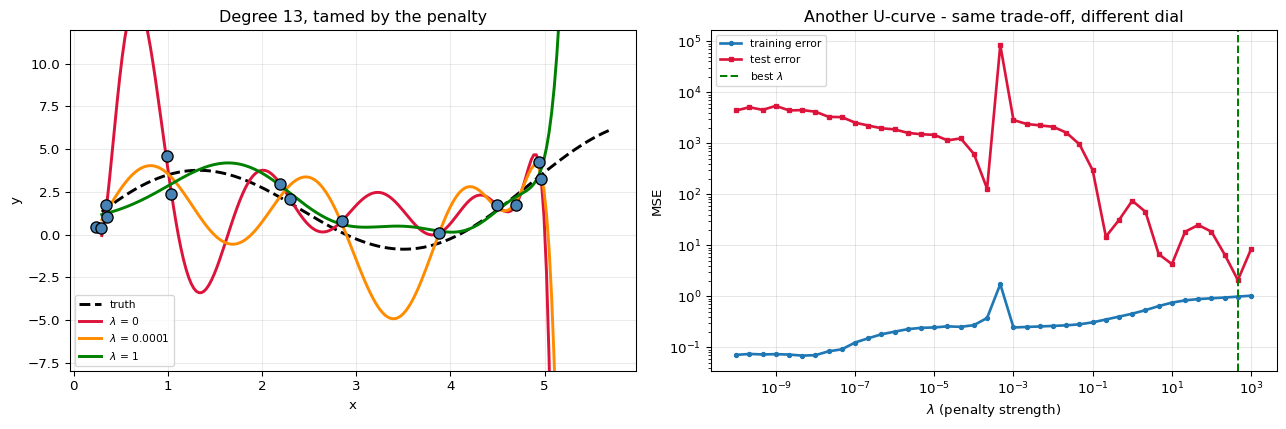


Too little penalty: overfitting, as before.
Too much penalty  : the coefficients are crushed to nothing and the model
                    underfits. Regularisation can cause EITHER failure.


In [17]:
from numpy.polynomial import polynomial as Poly

def ridge_poly(xs, ys, deg, lam):
    A = np.vander(xs, deg+1, increasing=True)
    Pen = lam*np.eye(deg+1); Pen[0, 0] = 0.0        # never penalise the intercept
    return np.linalg.solve(A.T @ A + Pen, A.T @ ys)

DEG = 13
print(f"a degree-{DEG} model - the one that overfitted badly - with increasing lambda\n")
print(f"{'lambda':>10}  {'train MSE':>11}  {'test MSE':>10}  {'max |coef|':>12}  "
      f"{'sum w^2':>12}")
print("-" * 62)
lams = [0.0, 1e-8, 1e-6, 1e-4, 1e-2, 1.0, 100.0]
tr_l, te_l = [], []
for lam in lams:
    co = ridge_poly(xs_fix, ys_fix, DEG, lam)
    pr_tr = np.vander(xs_fix, DEG+1, increasing=True) @ co
    pr_te = np.vander(x_te, DEG+1, increasing=True) @ co
    tr = float(np.mean((ys_fix - pr_tr)**2)); te = float(np.mean((y_te - pr_te)**2))
    tr_l.append(tr); te_l.append(te)
    print(f"{lam:>10.0e}  {tr:>11.5f}  {te:>10.4f}  {np.abs(co).max():>12.4g}  "
          f"{np.sum(co[1:]**2):>12.4g}")
print("-" * 62)
best_lam = lams[int(np.argmin(te_l))]
print(f"\nbest test error at lambda = {best_lam:.0e}")
print(f"   with no penalty  : train {tr_l[0]:.5f}, test {te_l[0]:.2f}")
print(f"   with the penalty : train {tr_l[int(np.argmin(te_l))]:.5f}, "
      f"test {min(te_l):.2f}")
print(f"\nTrain error got WORSE and test error got much better. That exchange is")
print(f"the entire purpose - and it is why judging a model by training error")
print(f"would have told you to throw the regularisation away.")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
ax = axes[0]
ax.plot(x_dom, f_true(x_dom), "k--", lw=2.2, label="truth")
for lam, col in [(0.0, "crimson"), (1e-4, "darkorange"), (1.0, "green")]:
    co = ridge_poly(xs_fix, ys_fix, DEG, lam)
    ax.plot(x_dom, np.vander(x_dom, DEG+1, increasing=True) @ co, lw=2.2,
            color=col, label=f"$\\lambda$ = {lam:g}")
ax.scatter(xs_fix, ys_fix, s=70, color="steelblue", edgecolor="k", zorder=5)
ax.set(ylim=(-8, 12), xlabel="x", ylabel="y",
       title=f"Degree {DEG}, tamed by the penalty")
ax.legend(fontsize=8); ax.grid(alpha=.25)

ax = axes[1]
lam_fine = np.logspace(-10, 3, 40)
trf = [float(np.mean((ys_fix - np.vander(xs_fix, DEG+1, increasing=True)
                      @ ridge_poly(xs_fix, ys_fix, DEG, l))**2)) for l in lam_fine]
tef = [float(np.mean((y_te - np.vander(x_te, DEG+1, increasing=True)
                      @ ridge_poly(xs_fix, ys_fix, DEG, l))**2)) for l in lam_fine]
ax.plot(lam_fine, trf, "o-", lw=2, ms=3, label="training error")
ax.plot(lam_fine, tef, "s-", lw=2, ms=3, color="crimson", label="test error")
ax.axvline(lam_fine[int(np.argmin(tef))], ls="--", color="green",
           label="best $\\lambda$")
ax.set(xscale="log", yscale="log", xlabel="$\\lambda$ (penalty strength)",
       ylabel="MSE", title="Another U-curve - same trade-off, different dial")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("\nToo little penalty: overfitting, as before.")
print("Too much penalty  : the coefficients are crushed to nothing and the model")
print("                    underfits. Regularisation can cause EITHER failure.")

---
# 10. What More Data Does

The last lever. A **learning curve** plots error against training-set size, and it
diagnoses which problem you have &mdash; which decides whether collecting more data is worth
the effort.

* **High variance (overfitting)** &mdash; a large gap between train and test error that
  **narrows** as data arrives. More data helps.
* **High bias (underfitting)** &mdash; both curves flatten early, close together, at a poor
  value. More data does **nothing**. You need a better model family, not a bigger sample.

This is one of the few pictures that tells you what to do next.

  n_train   deg1 train    deg1 test   deg9 train    deg9 test
------------------------------------------------------------
       15        4.112        5.337        0.329      993.042
       20        4.313        5.011        0.505      339.077
       30        4.591        4.911        0.672        1.905
       50        4.730        5.062        0.798        1.153
       90        4.931        4.817        0.860        1.055
      160        4.912        4.843        0.935        0.994
      320        5.120        4.929        0.956        0.976
      800        5.110        4.881        0.985        0.963
------------------------------------------------------------


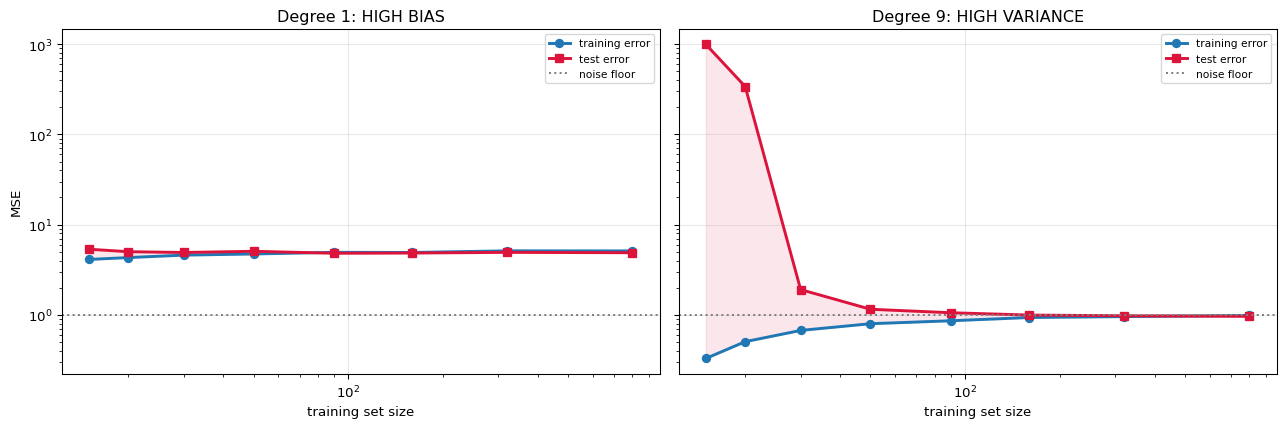


gap between test and train at n = 800:
   degree 1  : -0.2294   (already closed - and stuck well above the
               noise floor of 1.00, so the model itself is the limit)
   degree 9  : -0.0222   (closing as data arrives)

degree 9 at n= 15: test error   993.04
degree 9 at n=800: test error     0.96   -> data fixed it
degree  1 at n= 15: test error     5.34
degree  1 at n=800: test error     4.88   -> data changed nothing

Same problem, same extra data, opposite conclusions. That is why the
first question after a disappointing model is 'which curve am I on?'


In [18]:
sizes = [15, 20, 30, 50, 90, 160, 320, 800]
print(f"{'n_train':>9}  " + "  ".join(f"{'deg'+str(d)+' '+w:>11}"
                                      for d in (1, 9) for w in ("train", "test")))
print("-" * 60)
curves = {}
for deg in (1, 9):
    tr_s, te_s = [], []
    for m in sizes:
        a, b = [], []
        for _ in range(30):
            xs_m = rng.uniform(0, 6, m)
            ys_m = f_true(xs_m) + rng.normal(0, SIGMA, m)
            c = fit_poly(xs_m, ys_m, min(deg, m-1))
            a.append(np.mean((ys_m - np.polyval(c, xs_m))**2))
            b.append(np.mean((y_te - np.polyval(c, x_te))**2))
        tr_s.append(np.mean(a)); te_s.append(np.mean(b))
    curves[deg] = (tr_s, te_s)
for i, m in enumerate(sizes):
    print(f"{m:>9}  " + "  ".join(f"{curves[d][j][i]:>11.3f}"
                                  for d in (1, 9) for j in (0, 1)))
print("-" * 60)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)
for ax, deg, ttl in zip(axes, (1, 9),
                        ["Degree 1: HIGH BIAS", "Degree 9: HIGH VARIANCE"]):
    tr_s, te_s = curves[deg]
    ax.plot(sizes, tr_s, "o-", lw=2.2, label="training error")
    ax.plot(sizes, te_s, "s-", lw=2.2, color="crimson", label="test error")
    ax.axhline(SIGMA**2, ls=":", color="grey", label="noise floor")
    ax.fill_between(sizes, tr_s, te_s, color="crimson", alpha=.10)
    ax.set(xscale="log", yscale="log", xlabel="training set size",
           title=ttl)
    ax.legend(fontsize=8); ax.grid(alpha=.3)
axes[0].set_ylabel("MSE")
plt.tight_layout(); plt.show()

d1_gap = curves[1][1][-1] - curves[1][0][-1]
d12_gap = curves[9][1][-1] - curves[9][0][-1]
print(f"\ngap between test and train at n = {sizes[-1]}:")
print(f"   degree 1  : {d1_gap:+.4f}   (already closed - and stuck well above the")
print(f"               noise floor of {SIGMA**2:.2f}, so the model itself is the limit)")
print(f"   degree 9  : {d12_gap:+.4f}   (closing as data arrives)")
print()
print(f"degree 9 at n={sizes[0]:>3}: test error {curves[9][1][0]:>8.2f}")
print(f"degree 9 at n={sizes[-1]:>3}: test error {curves[9][1][-1]:>8.2f}   "
      f"-> data fixed it")
print(f"degree  1 at n={sizes[0]:>3}: test error {curves[1][1][0]:>8.2f}")
print(f"degree  1 at n={sizes[-1]:>3}: test error {curves[1][1][-1]:>8.2f}   "
      f"-> data changed nothing")
print(f"\nSame problem, same extra data, opposite conclusions. That is why the")
print(f"first question after a disappointing model is 'which curve am I on?'")

---
# 11. Where Each Concept Shows Up

Everything above is deliberately algorithm-free, because it applies to all of them. This
table maps each idea onto the specific walkthroughs, so a term met elsewhere can be
traced back here.

| Concept | In this notebook | Where it appears in the algorithms |
|---|---|---|
| **Loss** | section 2 | squared error (Linear Regression), log-loss (Logistic, Neural Net), hinge (SVM), Gini (Decision Tree), inertia (K-Means) |
| **Gradient** | section 4 | $X^\top(\mathbf{p}-\mathbf{y})$ in Logistic, $\delta$ in backpropagation, $g_i$ in XGBoost |
| **Learning rate** | section 5 | $\eta$ in Linear/Logistic/Neural Net, `eta` (shrinkage) in XGBoost and LightGBM |
| **Bias / variance** | section 6 | why forests average trees; why $k$ matters in KNN; why boosting adds shallow trees |
| **Overfitting** | section 7 | a single deep Decision Tree; RBF SVM with large $\gamma$; large `num_leaves` in LightGBM |
| **Held-out data** | section 8 | OOB error in Random Forest; leave-one-out in KNN |
| **Regularisation** | section 9 | ridge/lasso in Linear Regression; $C$ in SVM; $\lambda$ and $\gamma$ in XGBoost; ordered boosting in CatBoost |
| **Capacity** | sections 6&ndash;10 | polynomial degree here; tree depth; hidden units; number of components in PCA |

---
# 12. Summary

$$\text{total error} \;=\; \underbrace{\text{bias}^2}_{\text{too simple}}
\;+\; \underbrace{\text{variance}}_{\text{too sensitive}}
\;+\; \underbrace{\sigma^2}_{\text{unavoidable}}$$

**Six things worth carrying away:**

1. **Training turns dials, it does not invent shapes.** The family of possible answers was
   fixed when you chose the algorithm.
2. **The loss defines what "good" means.** Change it and you change the model's idea of a
   typical value &mdash; squared loss chases the mean, absolute loss the median.
3. **The gradient supplies direction; the learning rate supplies distance.** A correct
   direction with too large a step still diverges.
4. **Error has three parts, and they are measurable.** Bias and variance move in opposite
   directions; the noise floor cannot be crossed by any model.
5. **Training error is not quality.** Any sufficiently flexible model can drive it to
   zero by memorising, which is why held-out data is not optional.
6. **The learning curve tells you what to do next.** Gap still closing &rarr; get more data.
   Both curves flat and poor &rarr; more data will not help; change the model.

**What is deliberately left out:** momentum and adaptive optimisers (Adam), stochastic
gradient noise as implicit regularisation, the double-descent phenomenon in very
over-parameterised models, formal generalisation bounds (VC dimension, PAC learning),
nested cross-validation, and everything about data quality &mdash; leakage, drift, imbalance &mdash;
which matters enormously in practice and is a separate subject from how learning works.